# Reading the KV cache of Qwen3-4B (hand-picked sentences)

Three lenses on single-token KV slots, n=1 sentence per condition (anecdotal, not a measurement):
1. distance and attention: how much a token's K/V depend on its left context, and what each query attends to;
2. V lens: what a KV head's value at one token would write into the residual, read through the unembedding;
3. KV Patchscope: one token's KV (all or some layers) transplanted into a question prompt, and the model's answer.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from kvmeaning import model as M
from kvmeaning import reading as R
from kvmeaning.hooks import capture

plt.rcParams['font.family'] = ['Arial Unicode MS']
plt.rcParams['text.parse_math'] = False  # decoded tokens contain '$'
FIG = Path(os.environ.get('KV_FIG', '../figures/kv_reading'))
FIG.mkdir(parents=True, exist_ok=True)
model, tok = M.load('Q3-4B')
NL = len(M.kv_layers(model))
enc = lambda s: tok(s, add_special_tokens=False)['input_ids'] if s else []

BODY = ' The team released a new version on Monday.'
SRC = {
    'bank_first_river': ('', 'The bank was steep and muddy after the heavy rain.', 'bank'),
    'bank_first_money': ('', 'The bank raised its interest rates again.', 'bank'),
    'bank_ctx_river': ('', 'After the heavy rain the river rose, and the bank was steep and muddy.', 'bank'),
    'bank_ctx_money': ('', 'After the interest rates rose, the bank was full of angry customers.', 'bank'),
    'team_sport': ('The following passage is about sport.', BODY, 'team'),
    'team_tech': ('The following passage is about technology.', BODY, 'team'),
    'team_fillA': ('The weather today is mild and calm.', BODY, 'team'),
    'team_fillB': ('The library opens at nine every day.', BODY, 'team'),
}
S = {}
for name, (pre, body, word) in SRC.items():
    p, b = enc(pre), enc(body)
    ids = p + b
    S[name] = dict(ids=ids, body0=len(p), t=R.token_index(tok, ids, word, 0), cap=capture(model, torch.tensor([ids])))
    print(f'{name:18s} T={len(ids):3d} word@{S[name]["t"]}')

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

bank_first_river   T= 11 word@1
bank_first_money   T=  8 word@1


bank_ctx_river     T= 16 word@10
bank_ctx_money     T= 14 word@7


team_sport         T= 16 word@8
team_tech          T= 16 word@8


team_fillA         T= 17 word@9
team_fillB         T= 17 word@9


## 1. Does the same word get the same KV?

Causal masking means a token's K/V depend only on tokens to its left.
`bank` as the first word has identical left context in both sentences, so its KV should not differ (any residual is device noise).
`bank` after a disambiguating clause, and `team` after a sport/technology prefix, have different left context.
The filler pair (weather vs library prefix, same body) is the noise floor for `team`.

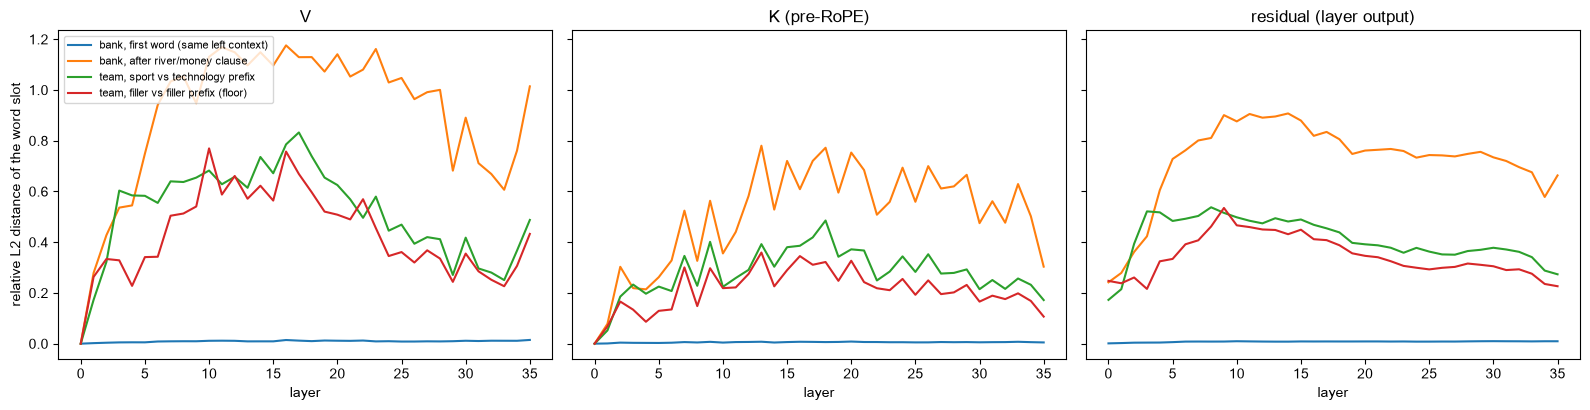

In [2]:
def rel(a, b):
    a, b = a.flatten(1), b.flatten(1)
    return ((a - b).norm(dim=1) / (0.5 * (a.norm(dim=1) + b.norm(dim=1)))).numpy()

PAIRS = [('bank, first word (same left context)', 'bank_first_river', 'bank_first_money'),
         ('bank, after river/money clause', 'bank_ctx_river', 'bank_ctx_money'),
         ('team, sport vs technology prefix', 'team_sport', 'team_tech'),
         ('team, filler vs filler prefix (floor)', 'team_fillA', 'team_fillB')]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, r in zip(axes, ('v', 'k_pre', 'resid')):
    for label, a, b in PAIRS:
        A, B = S[a], S[b]
        x = getattr(A['cap'], r)[:, :, A['t']] if r != 'resid' else A['cap'].resid[1:, A['t']][:, None]
        y = getattr(B['cap'], r)[:, :, B['t']] if r != 'resid' else B['cap'].resid[1:, B['t']][:, None]
        ax.plot(rel(x, y), label=label)
    ax.set_title({'v': 'V', 'k_pre': 'K (pre-RoPE)', 'resid': 'residual (layer output)'}[r])
    ax.set_xlabel('layer')
axes[0].set_ylabel('relative L2 distance of the word slot')
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig1_same_word_distance.png', dpi=130)

/var/folders/bw/zkbgtfrs3bg0c2p1d2fdx4qm0000gn/T/ipykernel_91323/1740585741.py:8: RuntimeWarning: invalid value encountered in divide
  ratio = d(A, B) / d(F1, F2)
/var/folders/bw/zkbgtfrs3bg0c2p1d2fdx4qm0000gn/T/ipykernel_91323/1740585741.py:8: RuntimeWarning: invalid value encountered in divide
  ratio = d(A, B) / d(F1, F2)


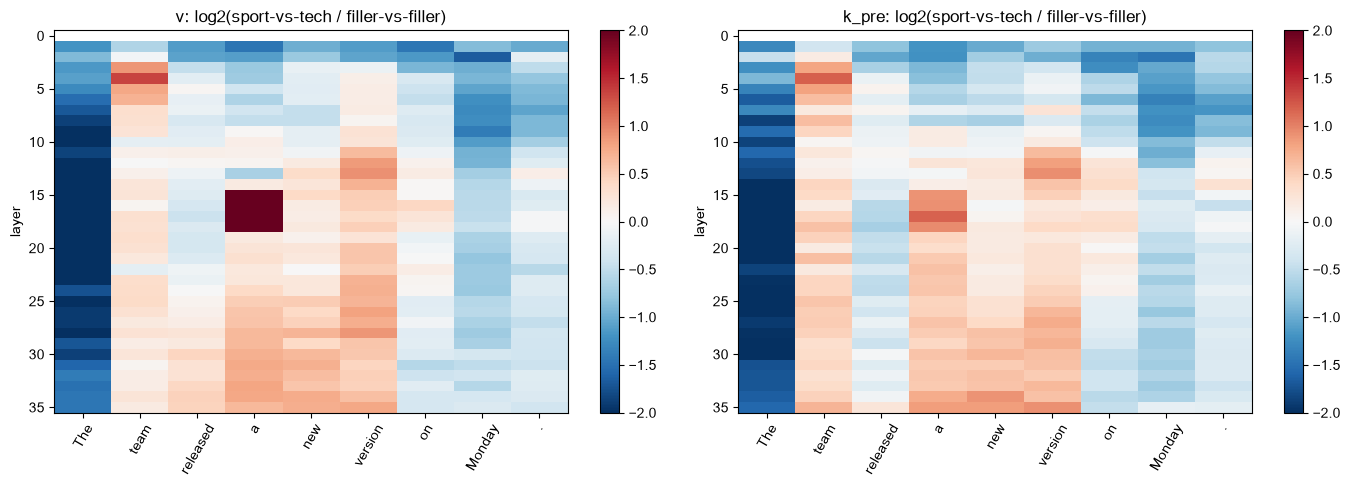

In [3]:
# Body tokens of the team sentence: sport-vs-technology distance divided by the filler-vs-filler distance.
A, B, F1, F2 = (S[k] for k in ('team_sport', 'team_tech', 'team_fillA', 'team_fillB'))
nb = len(enc(BODY))
labels = [tok.decode([i]) for i in A['ids'][A['body0']:]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, r in zip(axes, ('v', 'k_pre')):
    d = lambda X, Y: np.stack([rel(getattr(X['cap'], r)[:, :, X['body0'] + j], getattr(Y['cap'], r)[:, :, Y['body0'] + j]) for j in range(nb)], 1)
    ratio = d(A, B) / d(F1, F2)
    im = ax.imshow(np.log2(ratio), aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)
    ax.set_xticks(range(nb), labels, rotation=60); ax.set_ylabel('layer')
    ax.set_title(f'{r}: log2(sport-vs-tech / filler-vs-filler)')
    fig.colorbar(im, ax=ax)
fig.tight_layout(); fig.savefig(FIG / 'fig1b_body_vs_floor.png', dpi=130)

## 2. Attention: who reads whom

Attention is recomputed from the captured post-RoPE Q and K (eager math). Position 0 is an attention sink and is masked out and the rest renormalised.

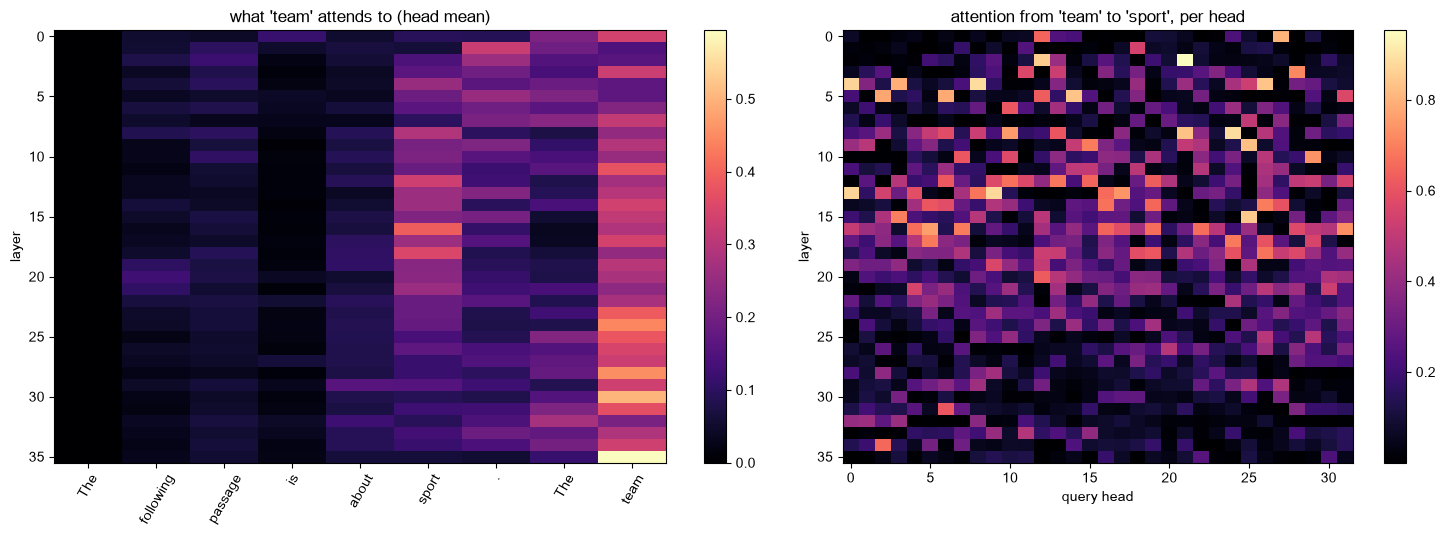

In [4]:
def no_sink(a):
    a = a.clone(); a[..., 0] = 0
    return a / a.sum(-1, keepdim=True).clamp_min(1e-12)

X = S['team_sport']
att = no_sink(R.attention_maps(X['cap']))  # [layer, head, T, T]
toks = [tok.decode([i]) for i in X['ids']]
t, sport = X['t'], R.token_index(tok, X['ids'], 'sport')
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw=dict(width_ratios=[1.2, 1]))
im = axes[0].imshow(att[:, :, t, :t + 1].mean(1), aspect='auto', cmap='magma')
axes[0].set_xticks(range(t + 1), toks[:t + 1], rotation=60); axes[0].set_ylabel('layer')
axes[0].set_title("what 'team' attends to (head mean)"); fig.colorbar(im, ax=axes[0])
im = axes[1].imshow(att[:, :, t, sport], aspect='auto', cmap='magma')
axes[1].set_xlabel('query head'); axes[1].set_ylabel('layer')
axes[1].set_title("attention from 'team' to 'sport', per head"); fig.colorbar(im, ax=axes[1])
fig.tight_layout(); fig.savefig(FIG / 'fig2a_team_attention.png', dpi=130)

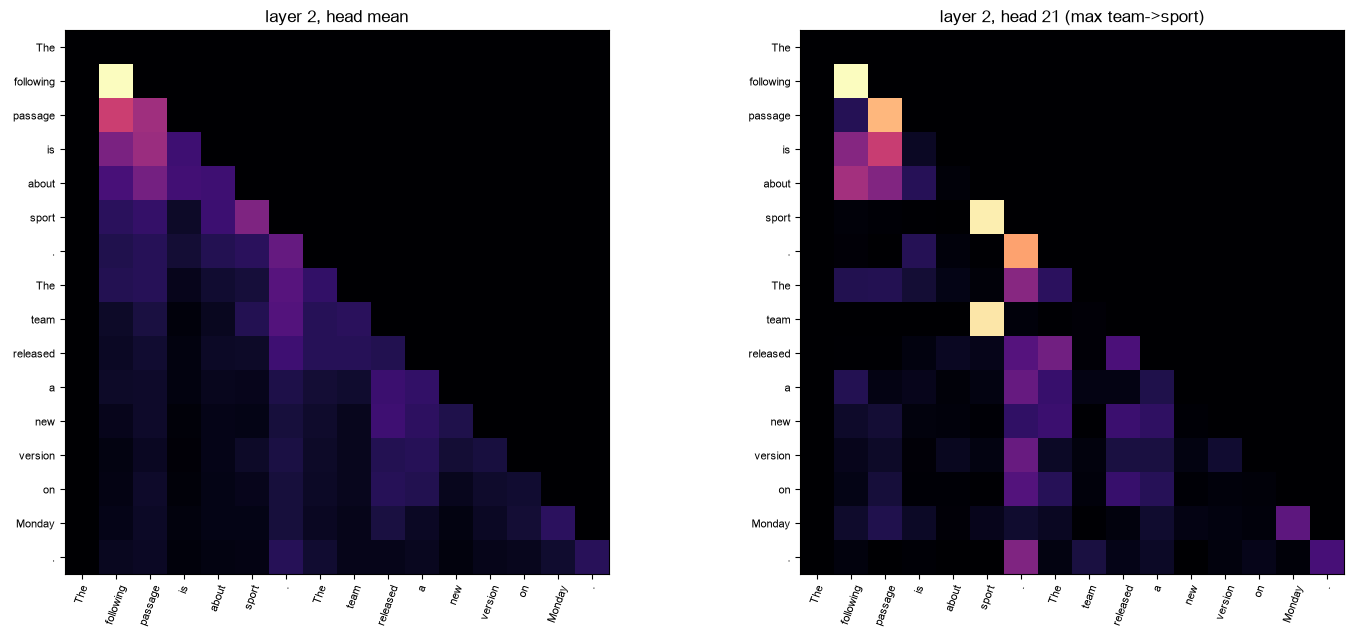

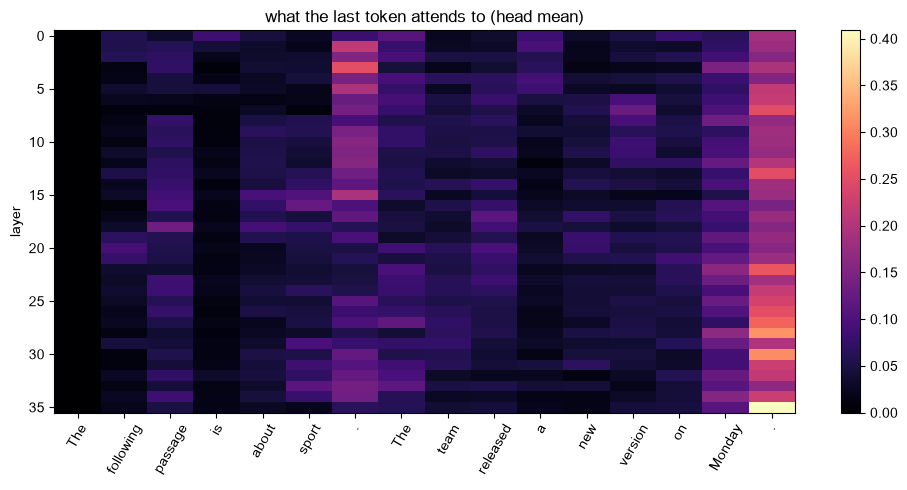

In [5]:
L, H = np.unravel_index(att[:, :, t, sport].argmax().item(), att.shape[:2])
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (m, title) in zip(axes, [(att[L].mean(0), f'layer {L}, head mean'), (att[L, H], f'layer {L}, head {H} (max team->sport)')]):
    ax.imshow(m, cmap='magma'); ax.set_title(title)
    ax.set_xticks(range(len(toks)), toks, rotation=70, fontsize=8); ax.set_yticks(range(len(toks)), toks, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig2b_attention_map.png', dpi=130)
last = len(toks) - 1
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(att[:, :, last].mean(1), aspect='auto', cmap='magma')
ax.set_xticks(range(len(toks)), toks, rotation=60); ax.set_ylabel('layer')
ax.set_title('what the last token attends to (head mean)'); fig.colorbar(im)
fig.tight_layout(); fig.savefig(FIG / 'fig2c_last_token_attention.png', dpi=130)

## 3. V lens: what a value would write

For one token, each KV head's value is pushed through the `o_proj` slices of the query heads that share it (GQA group of 4), giving the vector added to the residual if those heads attended only to that token; that vector is read through the final-norm weight and the unembedding.
Raw reads are mostly unreadable sub-word junk (shown first). Differences between two contexts of the same word are more legible.

raw V lens, team | sport prefix (top-3, KV heads 0-3):
  layer  0: ença 傷 _evaluati | 的风险 footage 史料 | .team 胶囊 -shift | 惜 填写 团队
  layer  5: middle 重心 安保 | lotte kitty sides | ',\n &\n ",\n | eer за 风光
  layer 10: stud 企业提供 paces | jer 了一批 Partners | � 佶 ANTE | jango ør ymous
  layer 15: 不分 发言人 ADED | otics 有名 anas | 立 granny 桄 | "[% }}>\n %+
  layer 20: individua stand stand | 卸 背 평 | Unhandled elor abee | aud atha 妻
  layer 25: )[ ())[ [/ | 了自己的 了几 了下来 | winning victory winners | Mate mate northwest
  layer 30: 成功 success 的成功 | Ｘ Python Scre | bias 偏 Tail | behind whole whole
  layer 35: is was has | praise famous ui | fle bee tile | eker cks -Identifi


) missing from font(s) Arial Unicode MS.
  fig.tight_layout(); fig.savefig(FIG / 'fig3_v_lens_diff.png', dpi=110)


) missing from font(s) Arial Unicode MS.
  func(*args, **kwargs)


) missing from font(s) Arial Unicode MS.
  fig.canvas.print_figure(bytes_io, **kw)


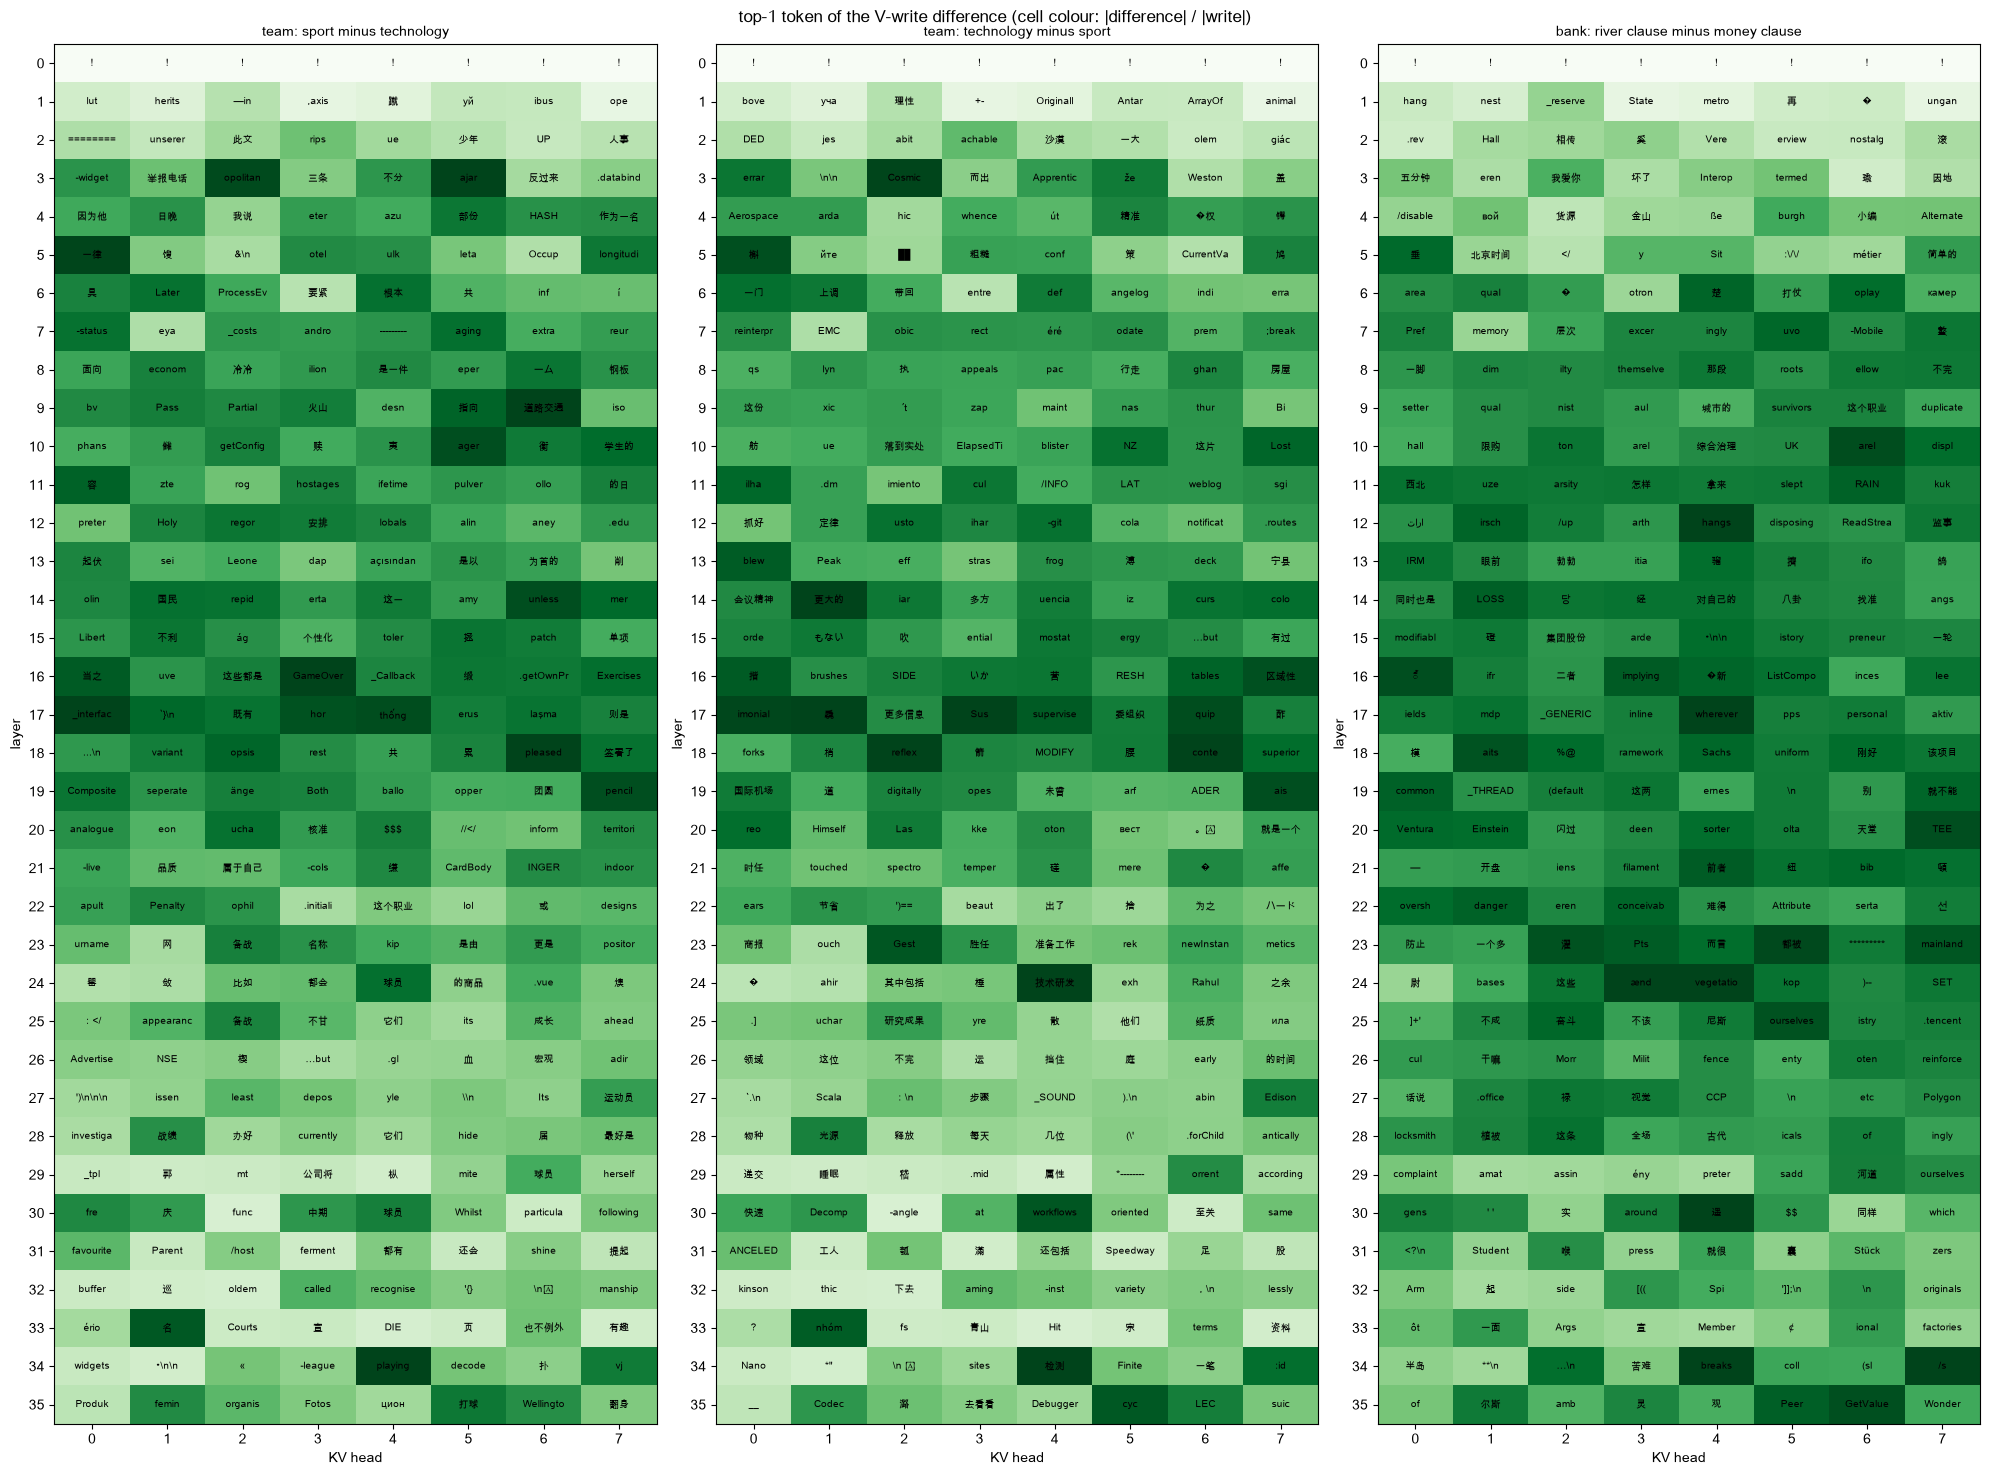

In [6]:
def clean(i):
    s = tok.decode([int(i)]).replace('\n', '\\n').strip() or repr(tok.decode([int(i)]))
    return s[:9]

def lens_grid(wa, wb, title, ax, layers):
    d = wa - wb
    _, ii = R.logit_lens(model, d, 1)
    mag = (d.norm(dim=-1) / wa.norm(dim=-1)).numpy()
    ax.imshow(mag[layers], aspect='auto', cmap='Greens', vmin=0, vmax=np.percentile(mag[layers], 98))
    for r, l in enumerate(layers):
        for h in range(d.shape[1]):
            ax.text(h, r, clean(ii[l, h, 0]), ha='center', va='center', fontsize=7)
    ax.set_yticks(range(len(layers)), layers); ax.set_xticks(range(d.shape[1]))
    ax.set_xlabel('KV head'); ax.set_ylabel('layer'); ax.set_title(title, fontsize=10)

wr = {k: R.v_writes(model, S[k]['cap'].v[:, :, S[k]['t']]) for k in S}
_, raw = R.logit_lens(model, wr['team_sport'], 3)
print('raw V lens, team | sport prefix (top-3, KV heads 0-3):')
for l in range(0, NL, 5):
    print(f'  layer {l:2d}:', ' | '.join(' '.join(clean(i) for i in raw[l, h]) for h in range(4)))

layers = list(range(NL))
fig, axes = plt.subplots(1, 3, figsize=(20, 15))
lens_grid(wr['team_sport'], wr['team_tech'], "team: sport minus technology", axes[0], layers)
lens_grid(wr['team_tech'], wr['team_sport'], "team: technology minus sport", axes[1], layers)
lens_grid(wr['bank_ctx_river'], wr['bank_ctx_money'], "bank: river clause minus money clause", axes[2], layers)
fig.suptitle('top-1 token of the V-write difference (cell colour: |difference| / |write|)')
fig.tight_layout(); fig.savefig(FIG / 'fig3_v_lens_diff.png', dpi=110)

## 4. KV Patchscope: ask the model what a single KV slot means

The placeholder `x` in a question prompt gets the donor token's KV at every layer (its key re-rotated to the placeholder position).
Everything else in the prompt is computed normally, so the answer reflects what later tokens can read out of that one slot.

(placeholder only) || The word "x" refers to an unknown value or variable. || None
bank | bank_first_river || A financial institution that accepts deposits and provides loans. || Finance
bank | bank_first_money || A financial institution that accepts deposits and provides loans. || Finance
bank | bank_ctx_river || The edge or side of a river, lake, or canal. || Geography
bank | bank_ctx_money || A financial institution that accepts deposits and provides loans. || Finance
team | team_sport || The team refers to a group of people working together toward a common goal. || Sports
team | team_tech || The team refers to a group of people working together. || Collaboration
team | team_fillA || The team refers to a group of people working together. || Sports
team | team_fillB || The team refers to a group of people working together. || Teamwork


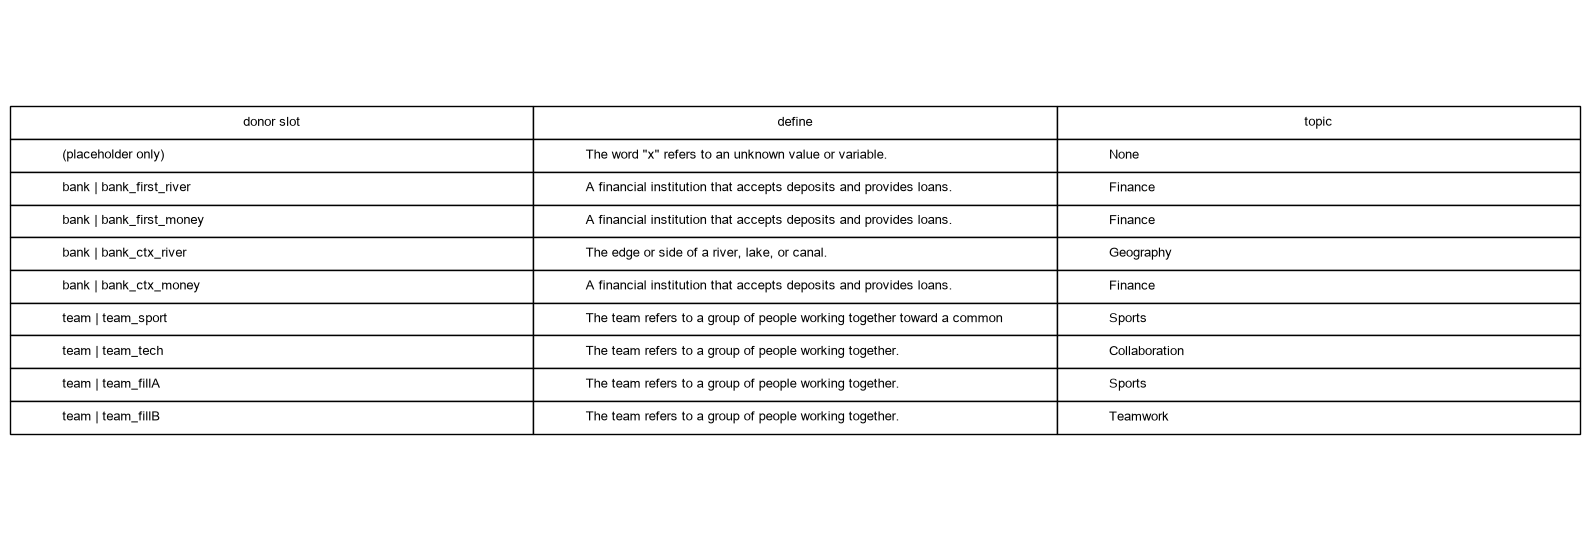

In [7]:
chat = lambda u: tok.apply_chat_template([{'role': 'user', 'content': u}], tokenize=False, add_generation_prompt=True)
TARGETS = {'define': chat('What does the word x refer to here? Answer in a few words.'),
           'topic': chat('x\n\nWhat topic is the word above about? Answer in one word.')}
T_IDS = {k: enc(v) for k, v in TARGETS.items()}
SLOT = {k: R.token_index(tok, v, 'x') for k, v in T_IDS.items()}
donor = lambda k: (S[k]['cap'].k_pre[:, :, S[k]['t']], S[k]['cap'].v[:, :, S[k]['t']])
rows = [['(placeholder only)'] + [R.transplant_generate(model, tok, T_IDS[g], SLOT[g], max_new=20) for g in TARGETS]]
for k in S:
    rows.append([f"{SRC[k][2]} | {k}"] + [R.transplant_generate(model, tok, T_IDS[g], SLOT[g], *donor(k), max_new=20) for g in TARGETS])
for r in rows:
    print(' || '.join(r))
fig, ax = plt.subplots(figsize=(16, 0.5 * len(rows) + 1)); ax.axis('off')
tb = ax.table(cellText=[[r[0]] + [c[:70] for c in r[1:]] for r in rows], colLabels=['donor slot'] + list(TARGETS), loc='center', cellLoc='left')
tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.6)
fig.tight_layout(); fig.savefig(FIG / 'fig4a_patchscope_table.png', dpi=130)

Which layers of the slot carry the answer? Transplant only layers `>= L` (solid) or only layers `< L` (dashed); the rest of the slot keeps the placeholder's own KV.
Read-out: log-probability gap between two answer words at the first answer token of the `topic` prompt.

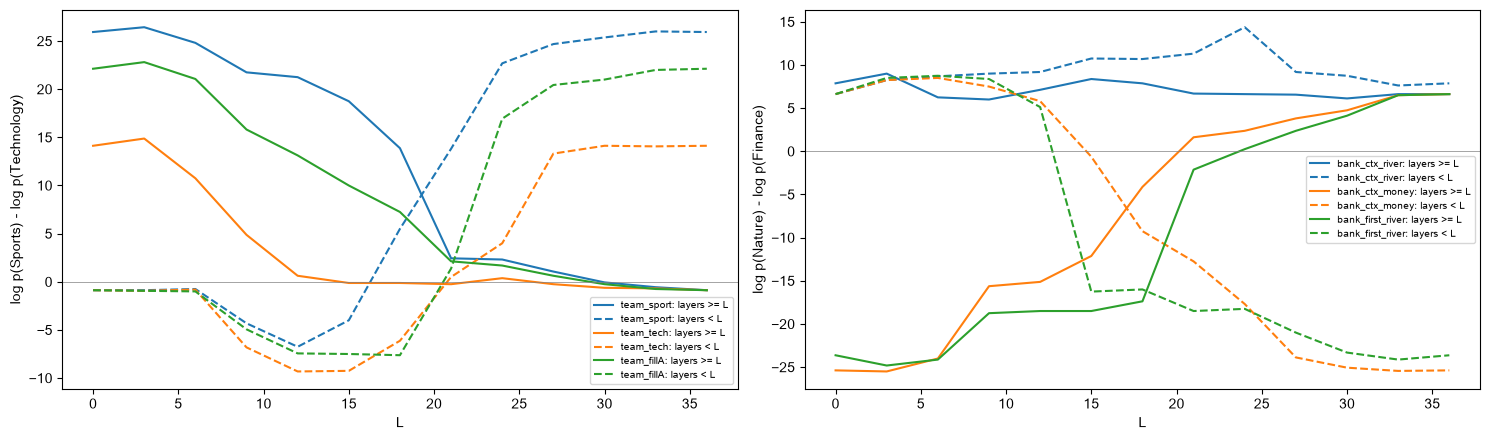

In [8]:
first = lambda w: enc(w)[0]
def gap(k, layers, a, b):
    out = R.transplant(model, T_IDS['topic'], SLOT['topic'], *donor(k), layers=layers)
    lp = out.logits[0, -1].float().log_softmax(-1).cpu()
    return (lp[first(a)] - lp[first(b)]).item()

cuts = list(range(0, NL + 1, 3)) + ([NL] if NL % 3 else [])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (keys, a, b) in zip(axes, [(['team_sport', 'team_tech', 'team_fillA'], 'Sports', 'Technology'),
                                    (['bank_ctx_river', 'bank_ctx_money', 'bank_first_river'], 'Nature', 'Finance')]):
    for k in keys:
        hi = [gap(k, set(range(L, NL)), a, b) for L in cuts]
        lo = [gap(k, set(range(L)), a, b) for L in cuts]
        p = ax.plot(cuts, hi, label=f'{k}: layers >= L')
        ax.plot(cuts, lo, '--', color=p[0].get_color(), label=f'{k}: layers < L')
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_xlabel('L'); ax.set_ylabel(f'log p({a}) - log p({b})'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / 'fig4b_patchscope_layers.png', dpi=130)